# MLflow local server initialization and Baseline experiment

In [14]:
### All imports are grouped in this cell ###

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from time import perf_counter

import mlflow
import mlflow.sklearn
import mlflow.sentence_transformers

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.preprocessing import normalize
from sklearn.cluster import kmeans_plusplus
from sklearn.utils.validation import check_is_fitted
from sklearn.cluster import HDBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
)
from sklearn.metrics import adjusted_rand_score

from sentence_transformers import SentenceTransformer

from bertopic.vectorizers import ClassTfidfTransformer

from scipy.sparse import csr_matrix

from spacy.lang.fr.stop_words import STOP_WORDS

import umap

from itertools import combinations


In [2]:
### Running the MLflow server locally ###

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Supply-chain-baseline")
print("Serveur MLflow:", mlflow.get_tracking_uri())

Serveur MLflow: http://127.0.0.1:5000


In [3]:
### Loading data ###

df_input = pd.read_csv('../data/raw/avis_24k_train.csv', header=0) # working with the first 24000 reviews only to reserve the remaining data for evaluation, testing and monitoring of the clustering.
display(df_input.info())
display(df_input.head())

<class 'pandas.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        24000 non-null  int64
 1   auteur            24000 non-null  str  
 2   note              24000 non-null  int64
 3   titre             24000 non-null  str  
 4   commentaire       24000 non-null  str  
 5   date_experience   24000 non-null  str  
 6   dataServiceReply  18252 non-null  str  
 7   lang              24000 non-null  str  
 8   date_to_sort      24000 non-null  str  
dtypes: int64(2), str(7)
memory usage: 10.8 MB


None

,Unnamed: 0,auteur,note,titre,commentaire,date_experience,dataServiceReply,lang,date_to_sort
0,0,Client,2,merci de vérifier vos stocks avant de…,merci de vérifier vos stocks avant de vous lan...,"April 24, 2024","Bonjour M, Nous comprenons votre frustration. ...",fr,2024-04-24
1,1,FARDOUX ERIC,3,problème de disques et plaquettes avant sur au...,"bonsoir, il y a un an, j'ai commandé des disqu...","April 25, 2024",NaN,fr,2024-04-25
2,2,setta,5,Parfait,Pièce qualité,"April 25, 2024","Bonjour Mohammed, Je vous remercie de votre re...",fr,2024-04-25
3,3,André Baudin,5,Pièces conformes et livraison rapide et…,Pièces conformes et livraison rapide et bien e...,"April 30, 2024","Bonjour André, Merci beaucoup pour votre comme...",fr,2024-04-30
4,4,Didier,1,Produits de mauvaise qualité sur Oscaro,"Le 14/05/2024, j'ai achété 2 biellettes de bar...","May 14, 2024","Bonjour Didier, Toutes nos excuses pour ce dés...",fr,2024-05-14


In [4]:
### Useful Functions ###

# For geometric evaluation of the clusters
def evaluate_clustering(X, labels):
    """
    X : L2 normalized inital embeddings
    labels : as produced by clustering
    """

    X = np.asarray(X)
    labels = np.asarray(labels)

    # Noise management: -1 stands for HDBSCAN noise
    assigned = labels != -1

    X_valid = X[assigned]
    y_valid = labels[assigned]

    # Count and size of the clusters
    unique, counts = np.unique(
        y_valid, return_counts=True
    )

    n_clusters = len(unique)

    # Coverage and noise ratio
    results = {
        "n_clusters": n_clusters,
        "coverage": float(assigned.mean()), # assigned = boolean array -> True considered as 1 by .mean()
        "noise_ratio": float(1 - assigned.mean()),
    }

    # Checking minimal count and size of clusters for score calculations
    if n_clusters < 2 or n_clusters >= len(y_valid):
        return results

    # Davies-Bouldin score
    results["davies_bouldin"] = float(
        davies_bouldin_score(X_valid, y_valid)
    )

    # silhouette score
    results["silhouette_cosine"] = float(
        silhouette_score(
            X_valid,
            y_valid,
            metric="cosine"
        )
    )

    # Data proportion represented by the biggest cluster
    results["largest_cluster_ratio"] = float(
        counts.max() / len(y_valid)
    )
   
    return results

# For clusters namming
def name_clustering(texts, labels):
    # Texts - Clusters association
    df = pd.DataFrame({
        "text": list(texts),
        "cluster": np.asarray(labels)
    })
    
    df["text"] = df["text"].fillna("").astype(str).str.strip()
    
    # Noise exclusion
    df = df[
        (df["cluster"] != -1) &
        (df["text"] != "")
    ].reset_index(drop=True)
    
    if df.empty:
        raise ValueError("Aucun document exploitable.")
    
    # Build Bag-of-words representation
    # Adapt stopwords to the tokenizer of CountVectorizer
    stop_words = sorted({
        token
        for word in STOP_WORDS
        for token in re.findall(r"(?u)\b\w\w+\b", word.lower())
    })
    
    vectorizer = CountVectorizer(
        stop_words=stop_words,
        ngram_range=(1, 2),
        min_df=1,
    )
    
    X_docs = vectorizer.fit_transform(df["text"])
    
    # Summing up occurencies per clusters
    cluster_labels, cluster_ids = np.unique(
        df["cluster"].to_numpy(),
        return_inverse=True
    )
    
    membership = csr_matrix(
        (
            np.ones(len(df)),
            (cluster_ids, np.arange(len(df)))
        ),
        shape=(len(cluster_labels), len(df))
    )
    
    X_clusters = membership @ X_docs
    
    # c-TF-IDF
    ctfidf_model = ClassTfidfTransformer()
    
    X_ctfidf = ctfidf_model.fit_transform(
        X_clusters
    ).tocsr()
    
    # Extraction of the most important terms
    vocabulary = vectorizer.get_feature_names_out()
    
    results = []
    
    for i, cluster_id in enumerate(cluster_labels):
        row = X_ctfidf.getrow(i)
    
        top_positions = np.argsort(row.data)[::-1][:10]
    
        for rank, pos in enumerate(top_positions, start=1):
            results.append({
                "cluster": int(cluster_id),
                "rank": rank,
                "term": vocabulary[row.indices[pos]],
                "score_ctfidf": float(row.data[pos])
            })
    
    df_keywords = pd.DataFrame(results)
    
    # Display main keywords for each cluster
    print(
        df_keywords.groupby("cluster")["term"]
        .apply(lambda s: ", ".join(s))
        .to_string()
    )

    # Return results

    return (df_keywords)

# For clustering stability evaluation
# Running the selected methods
def run_clustering(X, method, seed=42): # X: normalized embeddings

    if method == "kmeans":
        model = KMeans(
            n_clusters=K,
            n_init=10,
            random_state=seed
        )
        return model.fit_predict(X)

    elif method == "spherical_kmeans":
        model = SphericalKMeans(
            n_clusters=K,
            n_init=10,
            random_state=seed
        )
        return model.fit_predict(X)

    elif method == "hdbscan":
        model = HDBSCAN(**HDBSCAN_PARAMS)
        return model.fit_predict(X)

    elif method == "umap_hdbscan":
        reducer = umap.UMAP(
            **UMAP_PARAMS,
            random_state=seed
        )
        X_reduced = reducer.fit_transform(X)

        model = HDBSCAN(**HDBSCAN_UMAP_PARAMS)
        return model.fit_predict(X_reduced)

    else:
        raise ValueError(f"Méthode inconnue : {method}")

# running  the selected methods with verbose
def run_clustering_timed(X, method, seed, step):
    print(
        f"[START] {method} | {step} | "
        f"shape={X.shape}",
        flush=True
    )

    t0 = perf_counter()

    labels = run_clustering(
        X,
        method=method,
        seed=seed
    )

    print(
        f"[END] {method} | {step} | "
        f"duration={perf_counter() - t0:.1f}s",
        flush=True
    )

    return labels

# evaluating statistical and global stability 
def evaluate_stability(
    X,
    method,
    n_repeats=10,
    sample_fraction=0.8,
    mode="statistical",
    random_state=42
):
    if mode not in {"statistical", "global"}:
        raise ValueError("mode must be 'statistical' or 'global'")

    rng = np.random.default_rng(random_state)
    n_samples = len(X)
    sample_size = int(n_samples * sample_fraction)

    results = []

    for i in range(n_repeats):

        idx_a = np.sort(
            rng.choice(n_samples, sample_size, replace=False)
        )
        idx_b = np.sort(
            rng.choice(n_samples, sample_size, replace=False)
        )

        common, pos_a, pos_b = np.intersect1d(
            idx_a, idx_b, return_indices=True
        )

        if mode == "statistical":
            seed_a = random_state
            seed_b = random_state
        else:
            seed_a = random_state + 2 * i
            seed_b = random_state + 2 * i + 1

        labels_a = run_clustering_timed(
            X[idx_a], method, seed=seed_a,
            step=f"iteration {i+1}/{n_repeats} - A"
        )
        labels_b = run_clustering_timed(
            X[idx_b], method, seed=seed_b,
            step=f"iteration {i+1}/{n_repeats} - B"
        )

        ari = adjusted_rand_score(
            labels_a[pos_a],
            labels_b[pos_b]
        )

        results.append({
            "iteration": i,
            "method": method,
            "mode": mode,
            "ari": ari,
            "n_common": len(common)
        })

    return pd.DataFrame(results)

# evaluating algorithmic stability
def algorithmic_stability(
    X,
    method,
    n_repeats=10,
    base_seed=42
):
    partitions = []

    # same dataset for all executions
    for i in range(n_repeats):
        labels = run_clustering_timed(
            X,
            method=method,
            seed=base_seed + i,
            step=f"iteration {i+1}/{n_repeats}"
        )
        partitions.append(labels)

    # Comparing all pairs
    scores = [
        adjusted_rand_score(partitions[i], partitions[j])
        for i, j in combinations(range(n_repeats), 2)
    ]
    results = []
    for i in scores:
        results.append({
            "method": method,
            "mode": "algorithmic",
            "ari": i,
        })
        
    print({
        "method": method,
        "ari_mean": np.mean(scores),
        "ari_std": np.std(scores),
        "ari_min": np.min(scores),
        "ari_max": np.max(scores),
        "n_comparisons": len(scores)
    })

    return pd.DataFrame(results)

In [5]:
### Implementation of SphericalKMeans class ###

class SphericalKMeans(ClusterMixin, BaseEstimator):
    def __init__(self, n_clusters=10, max_iter=100,
                 n_init=5, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.n_init = n_init
        self.random_state = random_state

    def fit(self, X, y=None):
        X = normalize(np.asarray(X, dtype=np.float64))
        rng = np.random.default_rng(self.random_state)
        best_inertia = np.inf

        for _ in range(self.n_init):
            seed = int(rng.integers(0, 2**31 - 1))
            centers, _ = kmeans_plusplus(
                X, n_clusters=self.n_clusters,
                random_state=seed
            )
            centers = normalize(centers)

            for iteration in range(self.max_iter):
                labels = np.argmax(X @ centers.T, axis=1)

                new_centers = np.zeros_like(centers)
                np.add.at(new_centers, labels, X)

                # Réinitialiser les clusters vides
                empty = np.flatnonzero(
                    np.linalg.norm(new_centers, axis=1) == 0
                )
                for k in empty:
                    idx = rng.integers(len(X))
                    new_centers[k] = X[idx]

                new_centers = normalize(new_centers)

                if np.allclose(centers, new_centers, atol=1e-6):
                    centers = new_centers
                    break

                centers = new_centers

            labels = np.argmax(X @ centers.T, axis=1)
            similarities = np.sum(X * centers[labels], axis=1)
            inertia = np.sum(1 - similarities)

            if inertia < best_inertia:
                best_inertia = inertia
                self.cluster_centers_ = centers.copy()
                self.labels_ = labels.copy()
                self.inertia_ = float(inertia)
                self.n_iter_ = iteration + 1

        return self

    def predict(self, X):
        check_is_fitted(self, "cluster_centers_")
        X = normalize(np.asarray(X, dtype=np.float64))
        return np.argmax(X @ self.cluster_centers_.T, axis=1)

    def fit_predict(self, X, y=None):
        return self.fit(X).labels_


In [6]:
### Model uploading and embeddings generation

# input text formatting
texts=np.asarray(df_input['commentaire']) 

# model uploading
model_name = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
encoder = SentenceTransformer(
    model_name,
    trust_remote_code=False
)

# normalized embeddings generation
embeddings = encoder.encode(
    texts,
    normalize_embeddings=True,
    show_progress_bar=True,
)


Batches: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 750/750 [00:10<00:00, 70.57it/s]


In [26]:
### Clustering strategy n°1: Kmeans ###

kmeans_params = {
    "n_clusters": 10,
    "n_init": 10,
    "random_state": 42,
}

# One run only for the whole pipeline
with mlflow.start_run(run_name="mpnet-kmeans-k10") as run:

    # KMeans training
    kmeans = KMeans(**kmeans_params)
    labels = kmeans.fit_predict(embeddings)

    # parameters tracking
    mlflow.log_params({
        "embedding_model": model_name,
        "normalize_embeddings": True,
        **kmeans_params,
    })

    # metrics tracking
    metrics_clustering = evaluate_clustering(embeddings, labels)
    ctfidf_clustering = name_clustering(texts, labels)
    
    mlflow.log_metrics({
        "inertia": float(kmeans.inertia_),
        **metrics_clustering,
    })

    mlflow.log_table(
        data=ctfidf_clustering,
        artifact_file="interpretation/ctfidf_keywords.json"
    )

    # model tracking
    encoder_info = mlflow.sentence_transformers.log_model(
        model=encoder,
        name="sentence_transformer",
        input_example=list(texts[:2]),
    )

    # KMeans tracking
    kmeans_info = mlflow.sklearn.log_model(
        sk_model=kmeans,
        name="kmeans",
        input_example=embeddings[:2],
    )

    # pipeline configuration tracking
    mlflow.log_dict(
        {
            "encoder_uri": encoder_info.model_uri,
            "kmeans_uri": kmeans_info.model_uri,
            "normalize_embeddings": True,
        },
        "pipeline_config.json",
    )

print("Run ID :", run.info.run_id)
print("SentenceTransformer :", encoder_info.model_uri)
print("K-Means :", kmeans_info.model_uri)

Batches: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 750/750 [00:10<00:00, 72.19it/s]


cluster
0    facile, rapide, site, livraison, livraison rap...
1    bien, parfait, satisfait, bonne, rien, bon, bi...
2    prix, qualité, livraison, rapide, livraison ra...
3    véhicule, immatriculation, voiture, pièce, pla...
4    rapide, rapidité, livraison rapide, livraison,...
5    livraison, commande, conforme, délais, rapide,...
6    oscaro, commande, pièces, pièce, site, livrais...
7    commande, livraison, colis, jours, trop, long,...
8    carton, colis, emballage, arrivé, pièce, reçu,...
9    conforme, temps, bien, pièces, pièce, produit,...


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.92it/s]
2026/11/03 10:28:28 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 24405.45it/s]
2026/11/03 10:28:36 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run mpnet-kmeans-k10 at: http://127.0.0.1:5000/#/experiments/1/runs/320691ecaaa548d9928e8369e7792be9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run ID : 320691ecaaa548d9928e8369e7792be9
SentenceTransformer : models:/m-00990ff1055d4dadbc07a4cfcf0bcd3c
K-Means : models:/m-dc1834d6b5054c2f9eebb6b89b5e0000


In [ ]:
### Clustering strategy n°2: Spherical Kmeans ###

skmeans_params = {
    "n_clusters": 10,
    "max_iter": 100,
    "random_state": 42
}

with mlflow.start_run(run_name="mpnet_skmeans_k10"):

    # Spherical K-Means training
    skm = SphericalKMeans(**skmeans_params)
    
    labels = skm.fit_predict(embeddings)

    # parameters tracking
    mlflow.log_params({
        "model_name" : model_name,
        "normalize_embeddings" : True,
        **skmeans_params
    })

    # metrics tracking
    metrics_clustering = evaluate_clustering(embeddings, labels)
    ctfidf_clustering = name_clustering(texts, labels)

    mlflow.log_metrics({
        "inertia": float(skm.inertia_),
        **metrics_clustering,
    })

    mlflow.log_table(
        data=ctfidf_clustering,
        artifact_file="interpretation/ctfidf_keywords.json"
    )

    # model tracking
    encoder_info = mlflow.sentence_transformers.log_model(
        model=encoder,
        name="sentence_transformer",
        input_example=list(texts[:2]),
    )

    # Spherical KMeans tracking
    skmeans_info = mlflow.sklearn.log_model(
        sk_model=skm,
        name="spherical kmeans",
        input_example=embeddings_sparse[:2],
        skops_trusted_types=["__main__.SphericalKMeans"],
    )

    # pipeline configuration tracking
    mlflow.log_dict(
        {
            "encoder_uri": encoder_info.model_uri,
            "skmeans_uri": skmeans_info.model_uri,
            "normalize_embeddings": True,
        },
        "pipeline_config.json",
    )
    
print("Run ID :", run.info.run_id)
print("SentenceTransformer :", encoder_info.model_uri)
print("K-Means :", kmeans_info.model_uri)

In [8]:
### Clustering strategy n°3: HDBSCAN ###

hdbscan_params = {
    "min_cluster_size": 50,
    "min_samples": 10,
    "metric": "euclidean",
    "n_jobs": -1,
}

with mlflow.start_run(run_name="mpnet_hdbscan_mcs100") as run:

    # HDBSCAN training
    hdb = HDBSCAN(**hdbscan_params)
    labels = hdb.fit_predict(embeddings)

    # parameters tracking
    mlflow.log_params({
        "model_name": model_name,
        "normalize_embeddings": True,
        **hdbscan_params,
    })

    # metrics tracking
    metrics = evaluate_clustering(embeddings, labels)
    mlflow.log_metrics(metrics)

    ctfidf_clustering = name_clustering(texts, labels)
    mlflow.log_table(
        data=ctfidf_clustering,
        artifact_file="interpretation/ctfidf_keywords.json"
    )

    # model tracking
    encoder_info = mlflow.sentence_transformers.log_model(
        model=encoder,
        name="sentence_transformer",
        input_example=list(texts[:2]),
    )
    
    # HDBSCAN tracking
    hdbscan_info = mlflow.sklearn.log_model(
        sk_model=hdb,
        name="hdbscan",
    )

print("Run ID :", run.info.run_id)
print("HDBSCAN :", hdbscan_info.model_uri)



cluster
0     véhicule, immatriculation, pièce, plaque, plaq...
1     attentes, conforme attentes, conforme, corresp...
2     parfait, bien, rien, passé, bien passé, rien r...
3     satisfait, satisfaite, satisfaisant, content, ...
4     simple, simple rapide, facile, efficace, simpl...
5     trop, long, livraison trop, trop long, délais,...
6     efficace, rapide efficace, rapide, efficacité,...
7     qualité prix, qualité, prix, rapport qualité, ...
8     livraison rapide, livraison, rapide, livraison...
9     livraison rapide, conforme, livraison, produit...
10    rapidité livraison, rapidité, livraison, livra...


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.67it/s]
2026/11/04 10:43:18 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 15835.67it/s]
2026/11/04 10:43:22 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/11/04 10:43:24 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run mpnet_hdbscan_mcs100 at: http://127.0.0.1:5000/#/experiments/1/runs/6da9bdf541e3412da98d417ddcc9e9d4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run ID : 6da9bdf541e3412da98d417ddcc9e9d4
HDBSCAN : models:/m-bbe27a96399246588fd4cfb8ea58b98b


In [14]:
### Clustering strategy n°4: UMAP + HDBSCAN ###

umap_params = {
    "n_components": 15,
    "n_neighbors": 30,
    "min_dist": 0.0,
    "metric": "cosine",
    "random_state": 42,
}

hdbscan_params = {
    "min_cluster_size": 125,
    "min_samples": 10,
    "metric": "euclidean",
    "cluster_selection_method": "eom",
    "n_jobs": -1,
}

with mlflow.start_run(run_name="mpnet_umap_hdbscan_mcs125") as run:

    # Reducing dimensions with UMAP
    reducer = umap.UMAP(**umap_params)
    embeddings_umap = reducer.fit_transform(embeddings)

    # HDBSCAN training
    hdb = HDBSCAN(**hdbscan_params)
    labels = hdb.fit_predict(embeddings_umap)

    # parameters tracking
    mlflow.log_params({
        "model_name": model_name,
        "normalize_embeddings": True,
        **{f"umap_{k}": v for k, v in umap_params.items()},
        **{f"hdbscan_{k}": v for k, v in hdbscan_params.items()},
    })

    # metrics tracking
    mask = labels != -1
    metrics = evaluate_clustering(embeddings, labels)
    metrics["silhouette_umap"] = silhouette_score(
        embeddings_umap[mask],
        labels[mask],
        metric="euclidean",
    )

    mlflow.log_metrics(metrics)

    ctfidf_clustering = name_clustering(texts, labels)
    mlflow.log_table(
        data=ctfidf_clustering,
        artifact_file="interpretation/ctfidf_keywords.json"
    )

    # model tracking
    encoder_info = mlflow.sentence_transformers.log_model(
        model=encoder,
        name="sentence_transformer",
        input_example=list(texts[:2]),
    )

    # UMAP tracking
    # No input_example because no predict() function
    umap_info = mlflow.sklearn.log_model(
        sk_model=reducer,
        name="umap",
        serialization_format="cloudpickle",
    )

    # HDBSCAN tracking
    # No input_example because no predict() function
    hdbscan_info = mlflow.sklearn.log_model(
        sk_model=hdb,
        name="hdbscan",
    )

    # pipeline configuration tracking
    mlflow.log_dict(
        {
            "encoder_uri": encoder_info.model_uri,
            "umap_uri": umap_info.model_uri,
            "hdbscan_uri": hdbscan_info.model_uri,
            "normalize_embeddings": True,
            "clustering_metric": "euclidean",
        },
        "pipeline_config.json"
    )

print("Run ID :", run.info.run_id)
print("SentenceTransformer :", encoder_info.model_uri)
print("UMAP :", umap_info.model_uri)
print("HDBSCAN :", hdbscan_info.model_uri)


cluster
0    livraison rapide, rapide, livraison, rapide me...
1    nickel, livraison, livraison nickel, rapide, p...
2    batterie, livraison, batterie voiture, voiture...
3    véhicule, pièces, voiture, livraison, rapide, ...
4    rapide, livraison, livraison rapide, conforme,...
5    oscaro, commande, pièces, site, pièce, livrais...
6    colis, commande, livraison, pièce, trop, pièce...
7    glace, essuie, essuie glace, glaces, essuies, ...


Writing model shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.92it/s]
2026/11/04 11:01:21 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 9801.96it/s]
2026/11/04 11:01:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-le

🏃 View run mpnet_umap_hdbscan_mcs125 at: http://127.0.0.1:5000/#/experiments/1/runs/44c22a3610a9431188fcb8a178acc8a6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run ID : 44c22a3610a9431188fcb8a178acc8a6
SentenceTransformer : models:/m-bc6afb7ef27b48b7837b7a522d81aa47
UMAP : models:/m-9886f5b26fba4f7fa5bb79607be30fbb
HDBSCAN : models:/m-f6eb5e2063a349848842a4f8c4f0b1d9


In [27]:
### Statistical and algorithmic stability evaluation ###

# parameters setting (based on previous exploration phase)
K = 10
HDBSCAN_PARAMS = {
    "min_cluster_size": 50,
    "min_samples": 10,
    "metric": "euclidean",
}
HDBSCAN_UMAP_PARAMS = {
    "min_cluster_size": 130,
    "min_samples": 10,
    "metric": "euclidean",
}
UMAP_PARAMS = {
    "n_neighbors": 30,
    "n_components": 15,
    "min_dist": 0.0,
    "metric": "cosine",
}

methods = ["kmeans", "spherical_kmeans", "hdbscan", "umap_hdbscan"]
X = embeddings

In [20]:
### Statistical stability ###

# Adjusted rank index computation
stat_all_results = []
statistical_ARI_times_per_method = {}

for method in methods:

    print(f"\n===== {method.upper()} =====", flush=True)

    t0 = perf_counter()

    result = evaluate_stability(
        X,
        method=method,
        n_repeats=10
    )

    stat_all_results.append(result)

    statistical_ARI_times_per_method[method]=f"{perf_counter() - t0:.1f}s"
    print(
        f"{method} completed in "
        f"{perf_counter() - t0:.1f}s",
        flush=True
    )

print ("ARI computation complete !")


===== KMEANS =====
[START] kmeans | iteration 1/10 - A | shape=(19200, 768)
[END] kmeans | iteration 1/10 - A | duration=7.7s
[START] kmeans | iteration 1/10 - B | shape=(19200, 768)
[END] kmeans | iteration 1/10 - B | duration=8.4s
[START] kmeans | iteration 2/10 - A | shape=(19200, 768)
[END] kmeans | iteration 2/10 - A | duration=6.3s
[START] kmeans | iteration 2/10 - B | shape=(19200, 768)
[END] kmeans | iteration 2/10 - B | duration=6.4s
[START] kmeans | iteration 3/10 - A | shape=(19200, 768)
[END] kmeans | iteration 3/10 - A | duration=7.4s
[START] kmeans | iteration 3/10 - B | shape=(19200, 768)
[END] kmeans | iteration 3/10 - B | duration=6.0s
[START] kmeans | iteration 4/10 - A | shape=(19200, 768)
[END] kmeans | iteration 4/10 - A | duration=6.6s
[START] kmeans | iteration 4/10 - B | shape=(19200, 768)
[END] kmeans | iteration 4/10 - B | duration=6.7s
[START] kmeans | iteration 5/10 - A | shape=(19200, 768)
[END] kmeans | iteration 5/10 - A | duration=6.4s
[START] kmeans | 

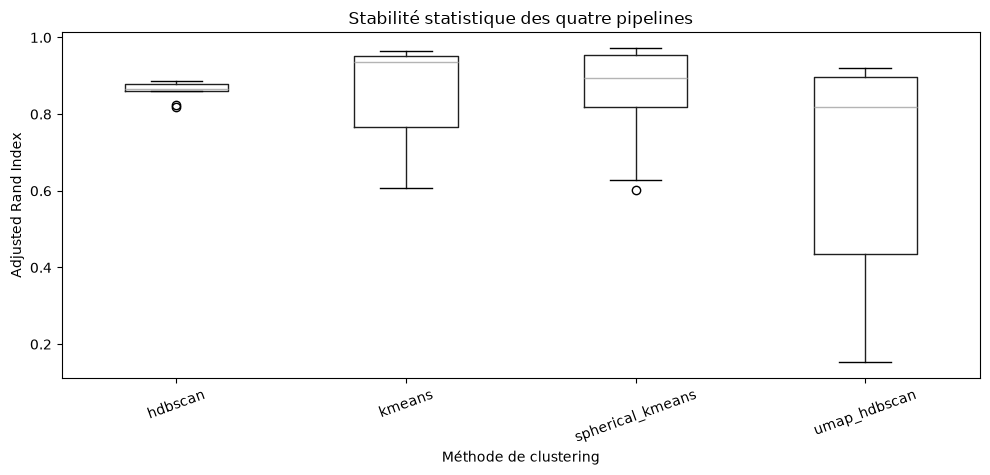

In [24]:
# Results plotting
fig, ax = plt.subplots(figsize=(10, 5))

results_2_plot = pd.concat(stat_all_results)


results_2_plot.boxplot(
    column="ari",
    by="method",
    ax=ax,
    grid=False
)

ax.set_title("Stabilité statistique des quatre pipelines")
ax.set_xlabel("Méthode de clustering")
ax.set_ylabel("Adjusted Rand Index")
ax.tick_params(axis="x", rotation=20)

plt.suptitle("")
plt.tight_layout()
plt.show()


In [28]:
### Algorithmic stability

# Adjusted rank index computation
alg_all_results = []
algorithmic_ARI_times_per_method = {}

for method in methods:

    print(f"\n===== {method.upper()} =====", flush=True)

    t0 = perf_counter()

    result = algorithmic_stability(
        X,
        method=method,
        n_repeats=10
    )

    alg_all_results.append(result)

    algorithmic_ARI_times_per_method[method]=f"{perf_counter() - t0:.1f}s"
    print(
        f"{method} completed in "
        f"{perf_counter() - t0:.1f}s",
        flush=True
    )

print ("ARI computation complete !")



===== KMEANS =====
[START] kmeans | iteration 1/10 | shape=(24000, 768)
[END] kmeans | iteration 1/10 | duration=8.4s
[START] kmeans | iteration 2/10 | shape=(24000, 768)
[END] kmeans | iteration 2/10 | duration=8.3s
[START] kmeans | iteration 3/10 | shape=(24000, 768)
[END] kmeans | iteration 3/10 | duration=8.0s
[START] kmeans | iteration 4/10 | shape=(24000, 768)
[END] kmeans | iteration 4/10 | duration=8.5s
[START] kmeans | iteration 5/10 | shape=(24000, 768)
[END] kmeans | iteration 5/10 | duration=7.9s
[START] kmeans | iteration 6/10 | shape=(24000, 768)
[END] kmeans | iteration 6/10 | duration=8.1s
[START] kmeans | iteration 7/10 | shape=(24000, 768)
[END] kmeans | iteration 7/10 | duration=7.0s
[START] kmeans | iteration 8/10 | shape=(24000, 768)
[END] kmeans | iteration 8/10 | duration=7.1s
[START] kmeans | iteration 9/10 | shape=(24000, 768)
[END] kmeans | iteration 9/10 | duration=7.0s
[START] kmeans | iteration 10/10 | shape=(24000, 768)
[END] kmeans | iteration 10/10 | du

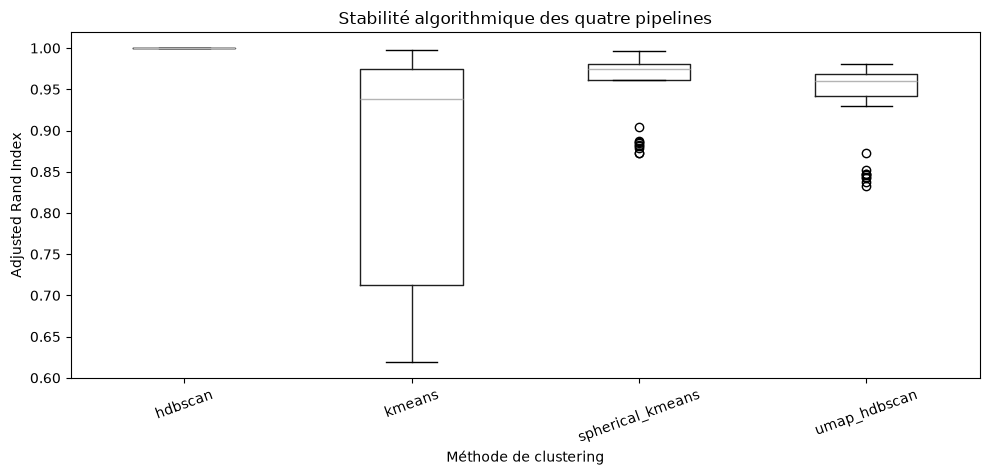

In [30]:
# Results plotting
fig, ax = plt.subplots(figsize=(10, 5))

results_2_plot = pd.concat(alg_all_results)


results_2_plot.boxplot(
    column="ari",
    by="method",
    ax=ax,
    grid=False
)

ax.set_title("Stabilité algorithmique des quatre pipelines")
ax.set_xlabel("Méthode de clustering")
ax.set_ylabel("Adjusted Rand Index")
ax.tick_params(axis="x", rotation=20)

plt.suptitle("")
plt.tight_layout()
plt.show()

In [31]:
### Global stability

# Adjusted rank index computation
glob_all_results = []
global_ARI_times_per_method = {}

for method in methods:

    print(f"\n===== {method.upper()} =====", flush=True)

    t0 = perf_counter()

    result = evaluate_stability(
        X,
        method=method,
        n_repeats=10,
        mode='global'
    )

    glob_all_results.append(result)

    global_ARI_times_per_method[method]=f"{perf_counter() - t0:.1f}s"
    print(
        f"{method} completed in "
        f"{perf_counter() - t0:.1f}s",
        flush=True
    )

print ("ARI computation complete !")



===== KMEANS =====
[START] kmeans | iteration 1/10 - A | shape=(19200, 768)
[END] kmeans | iteration 1/10 - A | duration=8.0s
[START] kmeans | iteration 1/10 - B | shape=(19200, 768)
[END] kmeans | iteration 1/10 - B | duration=6.3s
[START] kmeans | iteration 2/10 - A | shape=(19200, 768)
[END] kmeans | iteration 2/10 - A | duration=6.6s
[START] kmeans | iteration 2/10 - B | shape=(19200, 768)
[END] kmeans | iteration 2/10 - B | duration=7.1s
[START] kmeans | iteration 3/10 - A | shape=(19200, 768)
[END] kmeans | iteration 3/10 - A | duration=5.7s
[START] kmeans | iteration 3/10 - B | shape=(19200, 768)
[END] kmeans | iteration 3/10 - B | duration=7.1s
[START] kmeans | iteration 4/10 - A | shape=(19200, 768)
[END] kmeans | iteration 4/10 - A | duration=5.5s
[START] kmeans | iteration 4/10 - B | shape=(19200, 768)
[END] kmeans | iteration 4/10 - B | duration=6.5s
[START] kmeans | iteration 5/10 - A | shape=(19200, 768)
[END] kmeans | iteration 5/10 - A | duration=5.3s
[START] kmeans | 

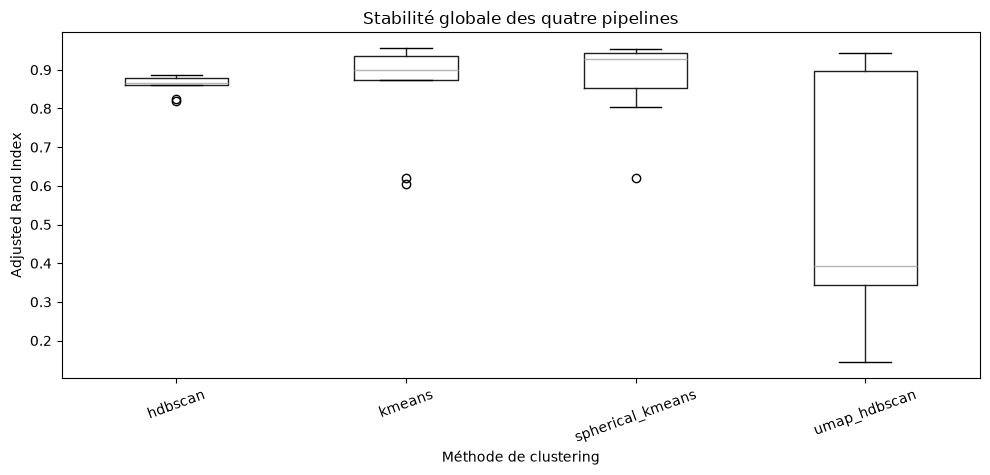

In [32]:
# Results plotting
fig, ax = plt.subplots(figsize=(10, 5))

results_2_plot = pd.concat(glob_all_results)


results_2_plot.boxplot(
    column="ari",
    by="method",
    ax=ax,
    grid=False
)

ax.set_title("Stabilité globale des quatre pipelines")
ax.set_xlabel("Méthode de clustering")
ax.set_ylabel("Adjusted Rand Index")
ax.tick_params(axis="x", rotation=20)

plt.suptitle("")
plt.tight_layout()
plt.show()